# step03_article_growth — Article Growth and Structural Evolution

Quantify observed page-size changes and flag candidate revisions for content-level follow-up.

Run cells from top to bottom. Shared helpers and file paths are in `analysis_common.py`. Outputs go to `analysis_results/` and `figures/`.

,article_title,first_timestamp,first_size_bytes,first_revision_id,last_timestamp,last_size_bytes,last_revision_id,net_change_bytes,growth_pct,average_annual_net_change_bytes,observed_span_years,revision_records
25,September 11 attacks,2001-11-21 16:01:18+00:00,4849,331585895,2026-11-08 04:06:59+00:00,327879,1384421083,323030.0,6.661786e+03,12940.414993,24.962878,22585
2,Arab Spring,2011-01-27 16:55:08+00:00,822,410393753,2026-11-06 18:20:00+00:00,303746,1384119973,302924.0,3.685207e+04,19201.594485,15.775982,10349
9,Cold War,2003-09-23 04:44:46+00:00,30,1493342,2026-10-23 06:27:29+00:00,296363,1381546396,296333.0,9.877767e+05,12837.443962,23.083489,12602
19,Korean War,2001-08-02 03:45:51+00:00,109,896535601,2026-11-08 06:54:49+00:00,288578,1384444415,288469.0,2.646505e+05,11416.149163,25.268503,14749
27,Vietnam War,2001-11-01 06:35:01+00:00,11303,349418001,2026-11-07 02:30:28+00:00,282986,1384196370,271683.0,2.403636e+03,10860.459945,25.015791,19378
16,Gulf War,2001-08-07 17:52:24+00:00,2217,1381292944,2026-11-09 07:38:32+00:00,262709,1384638139,260492.0,1.174975e+04,10314.053784,25.256025,14132
18,Iranian Revolution,2003-09-18 17:37:59+00:00,18,8520121,2026-10-29 22:03:22+00:00,244505,1382707136,244487.0,1.358261e+06,10577.480897,23.113916,6790
0,American Civil War,2001-11-02 23:28:55+00:00,4927,334930481,2026-11-09 17:51:56+00:00,242186,1384701279,237259.0,4.815486e+03,9483.397853,25.018354,14930
30,World War II,2001-11-10 00:51:27+00:00,11972,331657617,2026-11-10 01:56:48+00:00,247445,1384778963,235473.0,1.966864e+03,9418.937658,24.999953,28609
22,Partition of India,2003-07-11 06:23:36+00:00,386,2374543,2026-09-26 09:51:05+00:00,229900,1376809023,229514.0,5.945959e+04,9887.572834,23.212370,5863


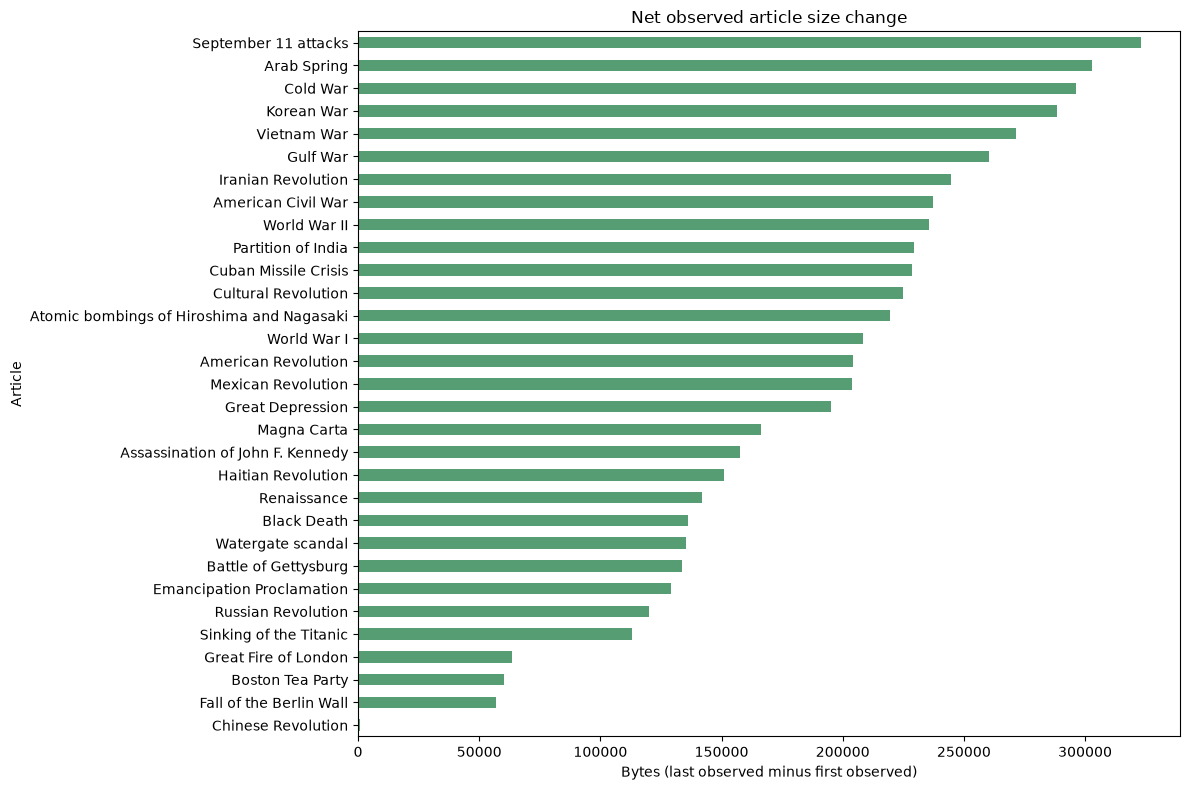

In [1]:
from pathlib import Path
import sys
from IPython.display import display
ROOT = Path.cwd().resolve()
while not (ROOT / 'analysis' / 'analysis_common.py').exists() and ROOT.parent != ROOT: ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'analysis'))
from analysis_common import *
df=load_revisions().dropna(subset=['timestamp','article_size_bytes']).sort_values(['article_title','timestamp','revision_id'])
growth_rows=[]
for article,g in df.groupby('article_title'):
    first,last=g.iloc[0],g.iloc[-1]; net=float(last.article_size_bytes-first.article_size_bytes)
    years=(last.timestamp-first.timestamp).total_seconds()/(365.2425*86400)
    growth_rows.append({'article_title':article,'first_timestamp':first.timestamp,'first_size_bytes':first.article_size_bytes,'first_revision_id':first.revision_id,'last_timestamp':last.timestamp,'last_size_bytes':last.article_size_bytes,'last_revision_id':last.revision_id,'net_change_bytes':net,'growth_pct':100*net/first.article_size_bytes if first.article_size_bytes else np.nan,'average_annual_net_change_bytes':net/years if years>0 else np.nan,'observed_span_years':years,'revision_records':len(g)})
growth=pd.DataFrame(growth_rows).sort_values('net_change_bytes',ascending=False)
save_table(growth,'step03_article_growth.csv'); display(growth)
fig,ax=plt.subplots(figsize=(12,8)); growth.sort_values('net_change_bytes').plot.barh(x='article_title',y='net_change_bytes',ax=ax,legend=False,color='#579d74'); ax.axvline(0,color='black',lw=.7); ax.set(title='Net observed article size change',xlabel='Bytes (last observed minus first observed)',ylabel='Article'); finish_plot(fig,'step03_net_growth.png')


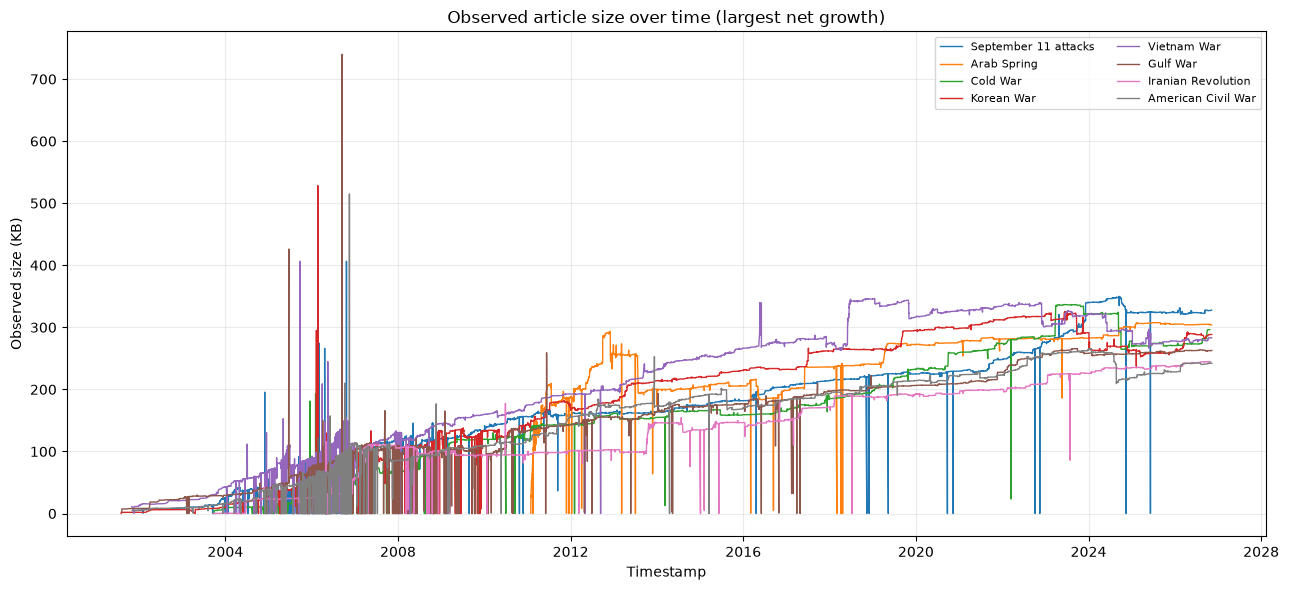

,article_title,timestamp,revision_id,parent_id,username,edit_comment,article_size_bytes,size_change_bytes,change_direction
201572,Russian Revolution,2005-10-25 19:23:47+00:00,26464652,26464358,Ritchy,rv vandalism to last version by Wikibofh,22662,-3537205.0,decrease
267007,World War I,2005-12-08 13:02:16+00:00,30587516,30567121,203.218.37.105,/* Causes */,2716074,2642330.0,increase
267008,World War I,2005-12-08 13:02:52+00:00,30587560,30587516,Ahoerstemeier,Reverted edits by [[Special:Contributions/203....,73744,-2642330.0,decrease
267009,World War I,2005-12-08 13:03:19+00:00,30587586,30587560,203.218.37.105,/* Causes */,2716074,2642330.0,increase
267010,World War I,2005-12-08 13:03:25+00:00,30587594,30587586,Ahoerstemeier,Reverted edits by [[Special:Contributions/203....,73744,-2642330.0,decrease
38231,Assassination of John F. Kennedy,2007-02-19 21:05:08+00:00,109385280,109384443,12.169.6.40,Removed glut of nonsense text,46974,-1716907.0,decrease
38229,Assassination of John F. Kennedy,2007-02-19 20:54:11+00:00,109382763,109381785,72.240.210.105,/* Autopsy */,1793519,1712164.0,increase
290446,World War II,2005-12-23 03:19:58+00:00,32441095,32440959,202.75.0.129,/* Participants */,1613424,1524224.0,increase
290447,World War II,2005-12-23 03:20:34+00:00,32441157,32441095,Titoxd,Reverted edits by [[Special:Contributions/202....,90696,-1522728.0,decrease
201569,Russian Revolution,2005-10-25 19:17:30+00:00,26464160,26464058,207.164.171.98,,2479931,1079816.0,increase


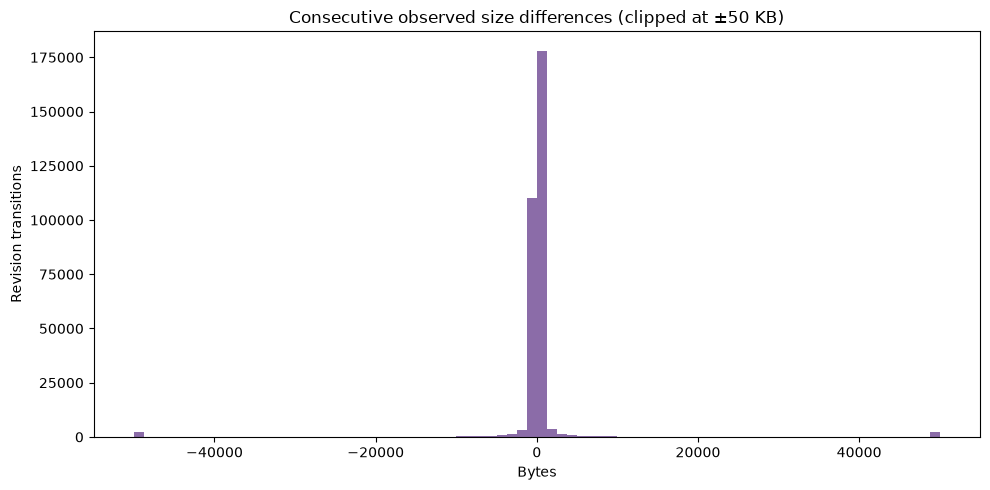

In [2]:
# Timeline samples use the observed revision metadata; the dataset may be sampled, so lines represent collected observations.
top=growth.nlargest(8,'net_change_bytes').article_title.tolist(); fig,ax=plt.subplots(figsize=(13,6))
for article in top:
    g=df[df.article_title.eq(article)]; ax.plot(g.timestamp,g.article_size_bytes/1000,label=article,lw=1)
ax.set(title='Observed article size over time (largest net growth)',xlabel='Timestamp',ylabel='Observed size (KB)'); ax.legend(fontsize=8,ncol=2); ax.grid(alpha=.25); finish_plot(fig,'step03_size_over_time.png')
changes=df.dropna(subset=['size_change_bytes']).copy()
large=changes.reindex(changes.size_change_bytes.abs().sort_values(ascending=False).index).head(100).copy()
large['change_direction']=np.where(large.size_change_bytes>0,'increase','decrease')
large=large[['article_title','timestamp','revision_id','parent_id','username','edit_comment','article_size_bytes','size_change_bytes','change_direction']]
save_table(large,'step03_largest_size_changes.csv'); display(large.head(30))
fig,ax=plt.subplots(figsize=(10,5)); ax.hist(changes.size_change_bytes.clip(-50000,50000),bins=80,color='#8b6ca8'); ax.set(title='Consecutive observed size differences (clipped at ±50 KB)',xlabel='Bytes',ylabel='Revision transitions'); finish_plot(fig,'step03_size_change_distribution.png')


## Content-level interpretation boundary

A size difference does not identify which paragraphs, claims, citations, or sections changed. The revision IDs and parent IDs in `step03_largest_size_changes.csv` are reproducible candidates for Step 5. Do not call these structural reorganizations until a revision diff has been inspected.